**Ashley Raber** 
**10/21/26** 
**Data in Emerging Media and Technology 12441.202680** 

## likes to posts API report

## Hypothesis
**Accounts with a higher total lifetime post count receive higher average likes on their recent posts.** 
### Theoretical & Statistical Application
* **Theoretical Context:** On social media platforms, accounts that publish content more often are going tobring in a stronger outreach on the algorithim making them have more engagement.  
* **Statistical Application:** I analyzed the relationship between an independent profile variable (`postsCount`) and a dependent post variable (`avg_likes`)

### Variables Identified
* **Independent Variable:**  `postsCount` (Lifetime total posts published by the account)
* **Dependent Variable:** `likeCount` (Number of likes received per post, averaged across recent activity)

## API Endpoints & Data Limitations

### Selected Endpoints
1. `app.bsky.actor.getProfiles`: Retrieves profile metadata including total followers and total posts.
2. `app.bsky.feed.getAuthorFeed`: Retrieves an account's recent feed items

### Data Reliability & Limitations
* **Reliability:** Bluesky's public endpoints allow direct access to live public data without requiring API keys or developer accounts.
* **Sampling issue:** `getAuthorFeed` returns only a recent sample of posts. Recent performance may reflect temporary viral spikes or quiet periods over long-term performance.
* **Missing Data Constraints:** Public endpoints do not show private metrics like impression counts, bookmarks, or people that just look, meaning engagement can only be evaluated through public actions (likes/reposts).

In [11]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# I used Ai to help me with this project. I was sick and missed a few 
#classes so i was definelty a little behind. but I explain what it all does 
#used to get endpoints
BASE_URL = "https://public.api.bsky.app/xrpc/"

# This is what was used to find active users
handles = [
    "victorbz.bsky.social",
    "bsky.app",
    "nytimes.com",
    "techcrunch.com",
    "theguardian.com",
    "verge.com"
]

# This gets the profile details from bluesky
profiles_url = f"{BASE_URL}app.bsky.actor.getProfiles"
response_profiles = requests.get(profiles_url, params={"actors": handles})

# This is just used to confirm i have access to the server
print(f"Profiles Request Status Code: {response_profiles.status_code}")
print(f"Requested URL: {response_profiles.url}\n")

profiles_json = response_profiles.json()
profiles_list = profiles_json.get("profiles", [])

# checking to see if it actuallly pulled profiles
if profiles_list:
    print("Profile Keys Available:", list(profiles_list[0].keys()))

#  empty list and acts as a storage bucket 
posts_data = []

for handle in handles:
    feed_url = f"{BASE_URL}app.bsky.feed.getAuthorFeed"
    response_feed = requests.get(feed_url, params={"actor": handle, "limit": 20})
    
    if response_feed.status_code == 200:
        feed_json = response_feed.json()
        feed_items = feed_json.get("feed", [])
        
        for item in feed_items:
            post = item.get("post", {})
            posts_data.append({
                "author_handle": post.get("author", {}).get("handle"),
                "author_did": post.get("author", {}).get("did"),
                "post_uri": post.get("uri"),
                "likeCount": post.get("likeCount", 0),
                "repostCount": post.get("repostCount", 0),
                "replyCount": post.get("replyCount", 0)
            })
            #  This sis going throiugh their recent posts and pulling 20 most recent and pulls out the posts data like lieks

print(f"\nSuccessfully collected {len(profiles_list)} user profiles and {len(posts_data)} recent posts.") #displays any info pulled

Profiles Request Status Code: 200
Requested URL: https://public.api.bsky.app/xrpc/app.bsky.actor.getProfiles?actors=victorbz.bsky.social&actors=bsky.app&actors=nytimes.com&actors=techcrunch.com&actors=theguardian.com&actors=verge.com

Profile Keys Available: ['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'description', 'indexedAt', 'banner', 'followersCount', 'followsCount', 'postsCount', 'pinnedPost']

Successfully collected 5 user profiles and 100 recent posts.


In [12]:
# This is creatinga  pandas data frame so it wasy to read
df_profiles = pd.DataFrame([
    {
        "did": p.get("did"),
        "handle": p.get("handle"),
        "displayName": p.get("displayName", ""),
        "followersCount": p.get("followersCount", 0),
        "postsCount": p.get("postsCount", 0)
    }
    for p in profiles_list
])


df_posts = pd.DataFrame(posts_data)


df_post_metrics = (
    df_posts.groupby("author_did")
    .agg(
        avg_likes=("likeCount", "mean"),
        avg_reposts=("repostCount", "mean"),
        posts_analyzed=("post_uri", "count")
    )
    .reset_index()
)

# this is merging the 2 data frame made
df_merged = pd.merge(
    df_profiles,
    df_post_metrics,
    left_on="did",
    right_on="author_did",
    how="inner"
)

#this is just sorting and making the final data frame
df_final = (
    df_merged.drop(columns=["author_did"])
    .sort_values(by="postsCount", ascending=False)
    .reset_index(drop=True)
)

df_final[["handle", "postsCount", "followersCount", "avg_likes", "avg_reposts"]]

,handle,postsCount,followersCount,avg_likes,avg_reposts
0,theguardian.com,64252,795655,46.117647,9.764706
1,nytimes.com,44692,1354143,177.450000,40.600000
2,techcrunch.com,20621,288632,14.100000,3.450000
3,victorbz.bsky.social,961,1321,12.350000,0.150000
4,bsky.app,896,35394599,825.166667,167.000000


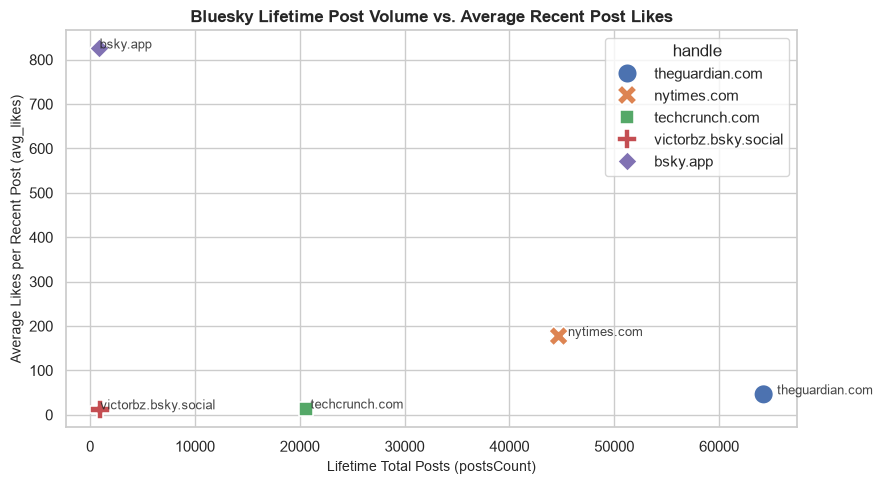

In [13]:
# this is just making the plot and sayign the size of it
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# This is actually making my scatter plot
scatter = sns.scatterplot(
    data=df_final,
    x="postsCount",
    y="avg_likes",
    hue="handle",
    style="handle",
    s=200
)

#this is just lableling everythin
for _, row in df_final.iterrows():
    plt.text(
        row["postsCount"] * 1.02, 
        row["avg_likes"], 
        row["handle"], 
        fontsize=9, 
        alpha=0.85
    )

plt.title("Bluesky Lifetime Post Volume vs. Average Recent Post Likes", fontsize=12, fontweight="bold")
plt.xlabel("Lifetime Total Posts (postsCount)", fontsize=10)
plt.ylabel("Average Likes per Recent Post (avg_likes)", fontsize=10)
plt.tight_layout()

plt.show()

## Conclusions & Reflection

### Conclusions
* **Data Summary:** Looking at the dataset, accounts with high total post counts do not consistently earn higher average likes per post.
* **Key Observations:** While active posting keeps an account visible, follower count and brand recognition make a bigger impact  in driving likes per post than total lifetime post volume alone.

### Limitations & Future Directions
* **Sample Size:** This dataset sampled active public accounts and analyzed their 20 most recent posts. A broader analysis across hundreds of non-institutional accounts would provide clearer trends.
* **Next Steps:** The next thing we could test is the frequecny of time like maybe some post more during the holidays and maybe that drives more interaction on the post.